In [82]:
import pandas as pd
df = pd.read_excel('../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb', sheet_name=0, header=2)
info = pd.read_excel('../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb', sheet_name=1)
df = df.merge(
    info[['АЗС', 'Подразделение']],
    left_on='Основная АЗС заправки',
    right_on='АЗС',
    how='left',
    validate='many_to_one'
)

In [83]:
volume_cols = df.columns[3:12]       # Объёмы заправок
gpn_price_cols = df.columns[12:21]    # Цены Газпромнефти
competitor_price_cols = df.columns[21:30]  # Цены конкурентов

In [84]:
df['Подразделение'].isna().sum()

np.int64(0)

In [85]:
df.head()

,Клиент,Основная АЗС заправки,Топливо,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,...,2023-10.2,2023-11.2,2023-12.2,2024-01.2,2024-02.2,2024-03.2,2024-04.2,2024-05.2,АЗС,Подразделение
0,ID_1,АЗС_926456,АИ-92,50.24,21.31,0.00,0.00,0.00,47.90,10.10,...,49.12,49.53,49.79,49.82,49.82,49.82,49.87,50.32,АЗС_926456,Ашхабад
1,ID_2,АЗС_659322,АИ-95,253.51,256.03,194.30,216.57,219.83,203.11,227.99,...,55.48,56.01,56.84,57.52,57.94,58.68,59.34,59.60,АЗС_659322,Душанбе
2,ID_3,АЗС_431208,АИ-92,61.17,20.46,61.56,42.21,42.07,87.07,20.00,...,51.97,52.44,52.94,53.32,53.55,53.68,53.93,54.60,АЗС_431208,Ереван
3,ID_4,АЗС_1499742,АИ-95,8.60,8.08,38.82,84.03,101.25,100.07,100.79,...,57.87,57.83,58.06,58.76,58.96,58.96,59.02,59.14,АЗС_1499742,Кишинев
4,ID_5,АЗС_1082534,АИ-95,53.82,151.54,344.31,266.22,240.10,250.59,101.42,...,59.33,59.12,56.39,56.72,57.13,57.23,57.87,58.17,АЗС_1082534,Астана


## Первичный анализ данных

In [86]:
print('Размер таблицы:', df.shape)
print('Столбцы:', df.columns.tolist())

Размер таблицы: (33146, 32)
Столбцы: ['Клиент', 'Основная АЗС заправки', 'Топливо', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2023-09.1', '2023-10.1', '2023-11.1', '2023-12.1', '2024-01.1', '2024-02.1', '2024-03.1', '2024-04.1', '2024-05.1', '2023-09.2', '2023-10.2', '2023-11.2', '2023-12.2', '2024-01.2', '2024-02.2', '2024-03.2', '2024-04.2', '2024-05.2', 'АЗС', 'Подразделение']


In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33146 entries, 0 to 33145
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Клиент                 33146 non-null  str    
 1   Основная АЗС заправки  33146 non-null  str    
 2   Топливо                33146 non-null  str    
 3   2023-09                33146 non-null  float64
 4   2023-10                33146 non-null  float64
 5   2023-11                33146 non-null  float64
 6   2023-12                33146 non-null  float64
 7   2024-01                33146 non-null  float64
 8   2024-02                33146 non-null  float64
 9   2024-03                33146 non-null  float64
 10  2024-04                33146 non-null  float64
 11  2024-05                33146 non-null  float64
 12  2023-09.1              33146 non-null  float64
 13  2023-10.1              33146 non-null  float64
 14  2023-11.1              33146 non-null  float64
 15  2023-12.1    

### Пропуски

In [88]:
pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков': df.isna().mean()
})

,Количество пропусков,Доля пропусков
Клиент,0,0.0
Основная АЗС заправки,0,0.0
Топливо,0,0.0
2023-09,0,0.0
2023-10,0,0.0
2023-11,0,0.0
2023-12,0,0.0
2024-01,0,0.0
2024-02,0,0.0
2024-03,0,0.0


### Дубликаты, клиенты и АЗС

In [89]:
print('Полных дубликатов строк:', df.duplicated().sum())

Полных дубликатов строк: 0


In [90]:
print('Уникальных клиентов:', df['Клиент'].nunique())
print('Уникальных АЗС:', df['Основная АЗС заправки'].nunique())

Уникальных клиентов: 33146
Уникальных АЗС: 642


### Числовые столбцы

In [91]:
df.describe()

,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2023-09.1,...,2024-05.1,2023-09.2,2023-10.2,2023-11.2,2023-12.2,2024-01.2,2024-02.2,2024-03.2,2024-04.2,2024-05.2
count,33146.000000,33146.000000,33146.000000,33146.00000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,...,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000
mean,120.646624,120.935653,113.282122,113.19644,95.791647,89.842459,86.141481,79.601833,82.362940,56.162631,...,60.217260,56.564270,56.686284,56.852049,57.443593,57.812539,58.074433,58.192671,58.411836,58.683162
std,163.049232,164.510494,163.706717,162.01791,131.124594,129.094056,124.046477,110.866097,110.270466,5.591560,...,5.077691,6.031771,5.429355,5.389537,4.780856,4.647720,4.639011,4.920583,5.133908,5.284646
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,45.140000,42.370000,0.000000,0.000000,0.000000
25%,44.650000,45.010000,40.702500,40.00000,32.425000,30.000000,23.692500,18.052500,17.980000,53.060000,...,56.790000,53.490000,53.560000,53.690000,54.200000,54.680000,54.940000,55.000000,55.280000,55.560000
50%,88.655000,88.340000,81.480000,80.65000,68.460000,62.990000,60.000000,54.560000,58.280000,56.320000,...,60.370000,55.960000,56.130000,56.450000,56.920000,57.430000,57.660000,57.640000,57.900000,58.360000
75%,151.067500,150.390000,139.957500,138.97750,122.127500,115.090000,113.700000,106.887500,113.007500,58.490000,...,62.600000,59.740000,59.530000,59.360000,59.420000,59.900000,60.050000,60.400000,60.610000,60.820000
max,12235.860000,13414.420000,9734.390000,5728.00000,5280.170000,5315.950000,4600.620000,4352.240000,5159.550000,77.100000,...,80.210000,85.000000,85.260000,87.180000,90.000000,90.000000,90.000000,90.000000,90.000000,88.450000


### Отрицательные и нулевые значения по месяцам

#### Объёмы заправок

In [92]:
pd.DataFrame({
    'Отрицательных': (df[volume_cols] < 0).sum(),
    'Нулевых': (df[volume_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09,0,2908
2023-10,0,2536
2023-11,0,2680
2023-12,0,2807
2024-01,0,3795
2024-02,0,4538
2024-03,0,5819
2024-04,0,6851
2024-05,0,6934


как видим количество нулевых заправок возрастает \
сигнализирует о снижении активности клиентов

#### Цены Газпромнефти

In [93]:
pd.DataFrame({
    'Отрицательных': (df[gpn_price_cols] < 0).sum(),
    'Нулевых': (df[gpn_price_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09.1,0,155
2023-10.1,0,99
2023-11.1,0,80
2023-12.1,0,8
2024-01.1,0,0
2024-02.1,0,0
2024-03.1,0,23
2024-04.1,0,43
2024-05.1,0,65


#### Цены конкурентов

In [94]:
pd.DataFrame({
    'Отрицательных': (df[competitor_price_cols] < 0).sum(),
    'Нулевых': (df[competitor_price_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09.2,0,155
2023-10.2,0,99
2023-11.2,0,80
2023-12.2,0,8
2024-01.2,0,0
2024-02.2,0,0
2024-03.2,0,23
2024-04.2,0,43
2024-05.2,0,65


### Категориальные столбцы

In [95]:
df.select_dtypes(include=['object', 'category', 'string']).nunique()

Клиент                   33146
Основная АЗС заправки      642
Топливо                      3
АЗС                        642
Подразделение               11
dtype: int64

## Анализ нулевых значений

### Совпадение нулевых цен по месяцам

In [96]:
gpn_zero = (df[gpn_price_cols] == 0).set_axis(volume_cols, axis=1)
competitor_zero = (df[competitor_price_cols] == 0).set_axis(volume_cols, axis=1)
zero_price_matches = gpn_zero == competitor_zero
pd.DataFrame({
    'Нулевые цены совпадают': zero_price_matches.all(),
    'Несовпадений': (~zero_price_matches).sum()
})

,Нулевые цены совпадают,Несовпадений
2023-09,True,0
2023-10,True,0
2023-11,True,0
2023-12,True,0
2024-01,True,0
2024-02,True,0
2024-03,True,0
2024-04,True,0
2024-05,True,0


### Нулевые цены при положительном объёме

In [97]:
positive_volume = df[volume_cols] > 0
zero_gpn_positive = gpn_zero & positive_volume
zero_competitor_positive = competitor_zero & positive_volume
pd.DataFrame({
    'Цена Газпромнефти': zero_gpn_positive.sum(),
    'Цена конкурентов': zero_competitor_positive.sum()
})

,Цена Газпромнефти,Цена конкурентов
2023-09,118,118
2023-10,80,80
2023-11,61,61
2023-12,6,6
2024-01,0,0
2024-02,0,0
2024-03,17,17
2024-04,32,32
2024-05,49,49


In [98]:
affected = (zero_gpn_positive | zero_competitor_positive).any(axis=1)
print('Нулевых цен при положительном объёме:', zero_gpn_positive.sum().sum())
print('Затронутых клиентов:', df.loc[affected, 'Клиент'].nunique())
print('Затронутых АЗС:', df.loc[affected, 'Основная АЗС заправки'].nunique())

Нулевых цен при положительном объёме: 363
Затронутых клиентов: 222
Затронутых АЗС: 9


### Нулевые объёмы и переходы между месяцами

Для первого месяца переходы не определяются: предыдущего месяца в таблице нет.

In [99]:
zero_volume = df[volume_cols] == 0
stopped = zero_volume & positive_volume.shift(axis=1, fill_value=False)
resumed = positive_volume & zero_volume.shift(axis=1, fill_value=False)
volume_activity = pd.DataFrame({
    'Нулевой объём': zero_volume.sum(),
    'Прекратили покупки': stopped.sum(),
    'Возобновили покупки': resumed.sum()
})
volume_activity

,Нулевой объём,Прекратили покупки,Возобновили покупки
2023-09,2908,0,0
2023-10,2536,1629,2001
2023-11,2680,2035,1891
2023-12,2807,2163,2036
2024-01,3795,2879,1891
2024-02,4538,3119,2376
2024-03,5819,3967,2686
2024-04,6851,3734,2702
2024-05,6934,3079,2996


### Динамика нулевых объёмов

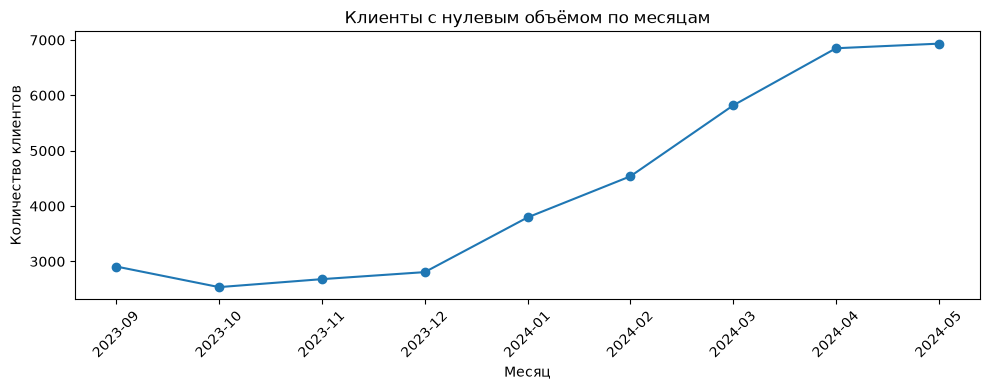

In [100]:
import matplotlib.pyplot as plt

volume_activity['Нулевой объём'].plot(marker='o', figsize=(10, 4))
plt.title('Клиенты с нулевым объёмом по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Прекращение и возобновление покупок

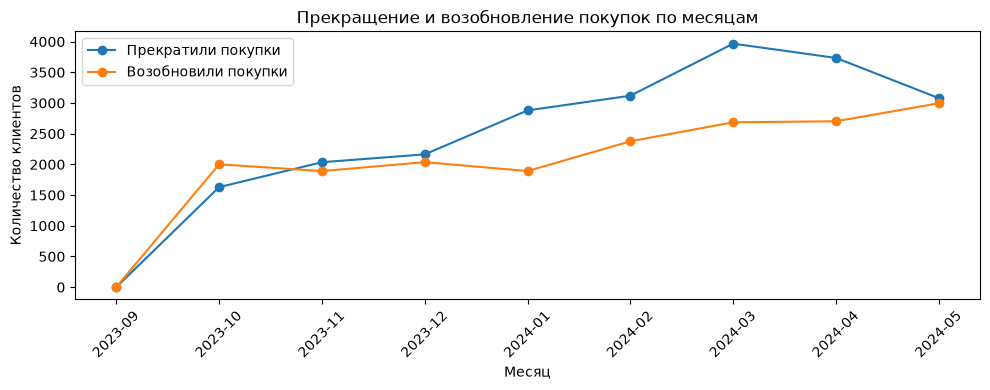

In [101]:
volume_activity[['Прекратили покупки', 'Возобновили покупки']].plot(marker='o', figsize=(10, 4))
plt.title('Прекращение и возобновление покупок по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Динамика цен и объёмов заправок

In [102]:
price_parts = []
for month, gpn_col, competitor_col in zip(volume_cols, gpn_price_cols, competitor_price_cols):
    prices = df[['Основная АЗС заправки', 'Топливо', gpn_col, competitor_col]].drop_duplicates(
        subset=['Основная АЗС заправки', 'Топливо']
    ).copy()
    prices.columns = ['АЗС', 'Топливо', 'Цена Газпромнефти', 'Цена конкурентов']
    prices['Месяц'] = month
    price_parts.append(prices)

station_prices = pd.concat(price_parts, ignore_index=True)

In [103]:
station_prices['Цена Газпромнефти'] = station_prices['Цена Газпромнефти'].mask(
    station_prices['Цена Газпромнефти'] == 0
)
station_prices['Цена конкурентов'] = station_prices['Цена конкурентов'].mask(
    station_prices['Цена конкурентов'] == 0
)
station_prices['Разница цен'] = station_prices['Цена Газпромнефти'] - station_prices['Цена конкурентов']

### Показатели по месяцам

In [104]:
monthly_metrics = station_prices.groupby('Месяц', sort=False)[
    ['Цена Газпромнефти', 'Цена конкурентов', 'Разница цен']
].mean().rename(columns={
    'Цена Газпромнефти': 'Средняя цена Газпромнефти',
    'Цена конкурентов': 'Средняя цена конкурентов',
    'Разница цен': 'Средняя разница цен'
})
monthly_metrics['Суммарный объём'] = df[volume_cols].sum()
monthly_metrics['Клиентов с положительным объёмом'] = (df[volume_cols] > 0).sum()
monthly_metrics

,Средняя цена Газпромнефти,Средняя цена конкурентов,Средняя разница цен,Суммарный объём,Клиентов с положительным объёмом
Месяц,,,,,
2023-09,58.322667,58.284243,0.038425,3998952.997,30238
2023-10,58.686395,58.431233,0.255162,4008533.170,30610
2023-11,59.237106,59.039316,0.197790,3754849.219,30466
2023-12,60.195866,59.736040,0.459826,3752009.195,30339
2024-01,60.803566,60.078291,0.725275,3175109.942,29351
2024-02,61.038938,60.265531,0.773408,2977918.134,28608
2024-03,61.641673,60.417929,1.223744,2855245.533,27327
2024-04,62.079711,60.629738,1.449973,2638482.349,26295
2024-05,62.351709,60.864345,1.487364,2730002.009,26212


### Динамика средних цен

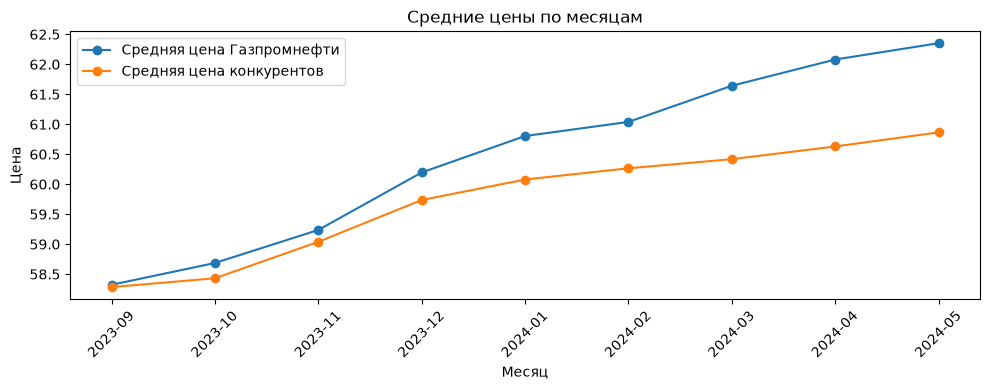

In [105]:
monthly_metrics[['Средняя цена Газпромнефти', 'Средняя цена конкурентов']].plot(
    marker='o', figsize=(10, 4)
)
plt.title('Средние цены по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Цена')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Динамика средней разницы цен

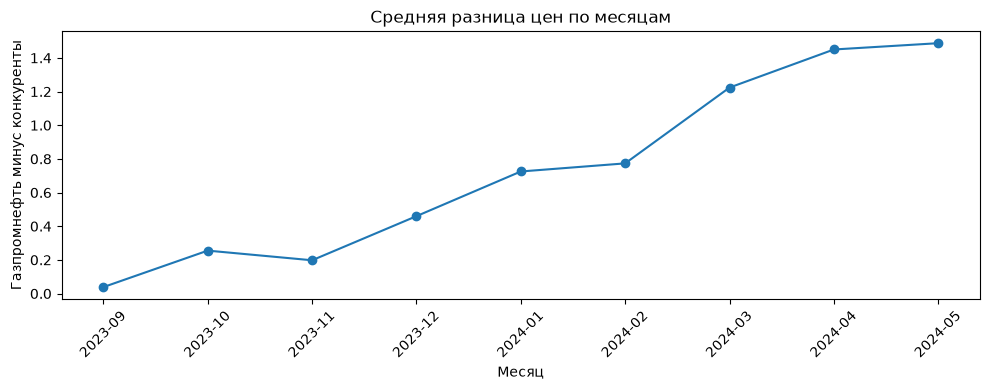

In [106]:
monthly_metrics['Средняя разница цен'].plot(marker='o', figsize=(10, 4))
plt.title('Средняя разница цен по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Газпромнефть минус конкуренты')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Динамика суммарного объёма

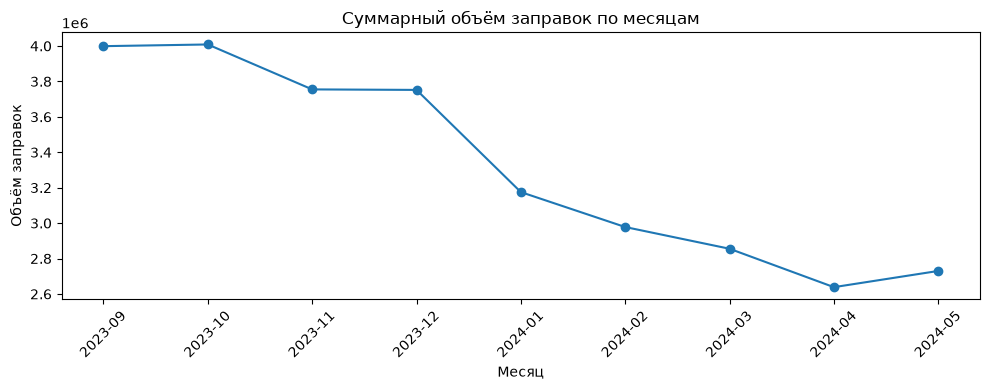

In [107]:
monthly_metrics['Суммарный объём'].plot(marker='o', figsize=(10, 4))
plt.title('Суммарный объём заправок по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Объём заправок')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Разница цен и объёмы по видам топлива

In [108]:
fuel_price_diff = station_prices.groupby(['Топливо', 'Месяц'])['Разница цен'].mean()
fuel_volume = df.groupby('Топливо')[volume_cols].sum().stack()
fuel_metrics = pd.concat([
    fuel_price_diff.rename('Средняя разница цен'),
    fuel_volume.rename('Суммарный объём')
], axis=1)
fuel_metrics.index.names = ['Топливо', 'Месяц']
fuel_metrics

Средняя разница цен  Суммарный объём
Топливо Месяц                                        
АИ-92   2023-09             0.008294      1115045.089
        2023-10             0.184164      1129033.356
        2023-11             0.473622      1041721.295
        2023-12             0.761099      1033132.875
        2024-01             0.861050       880478.855
        2024-02             0.762743       823450.428
        2024-03             1.150534       785248.927
        2024-04             1.296923       732329.813
        2024-05             1.213129       749162.095
АИ-95   2023-09            -0.401248      2325769.563
        2023-10            -0.067587      2295566.579
        2023-11             0.481354      2067101.286
        2023-12             1.028762      2027223.808
        2024-01             1.285533      1762401.094
        2024-02             1.184702      1637524.163
        2024-03             1.624662      1608873.582
        2024-04             1.904349      1511279.511
        2024-05             1.838601      1598613.219
ДТ      2023-09             0.573291       558138.345
        2023-10             0.703339       583933.235
        2023-11            -0.438799       646026.638
        2023-12            -0.529287       691652.512
        2024-01            -0.066292       532229.993
        2024-02             0.317790       516943.543
        2024-03             0.851640       461123.024
        2024-04             1.107214       394873.025
        2024-05             1.399911       382226.695

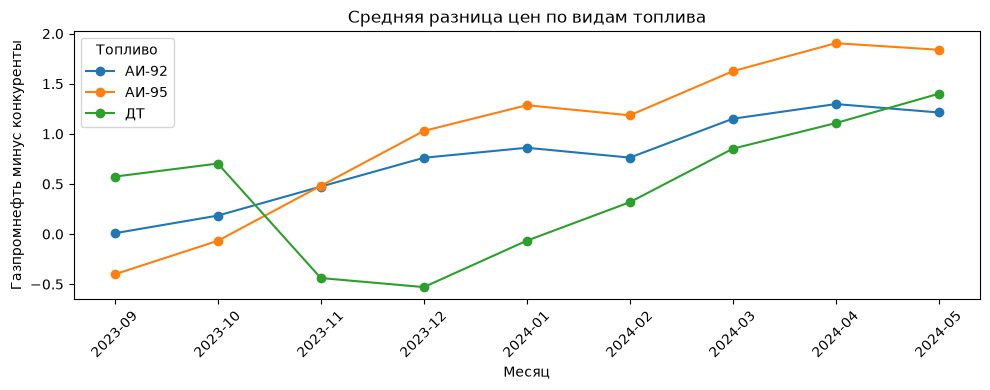

In [109]:
fuel_metrics['Средняя разница цен'].unstack('Топливо').plot(marker='o', figsize=(10, 4))
plt.title('Средняя разница цен по видам топлива')
plt.xlabel('Месяц')
plt.ylabel('Газпромнефть минус конкуренты')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Изменение разницы цен между соседними месяцами

In [110]:
price_change = monthly_metrics['Средняя разница цен'].diff().dropna()
pd.Series({
    'Увеличивалась': (price_change > 0).sum(),
    'Уменьшалась': (price_change < 0).sum(),
    'Не менялась': (price_change == 0).sum()
})

Увеличивалась    7
Уменьшалась      1
Не менялась      0
dtype: int64

In [111]:
fuel_price_change = fuel_metrics['Средняя разница цен'].unstack('Топливо').diff().iloc[1:]
pd.DataFrame({
    'Увеличивалась': (fuel_price_change > 0).sum(),
    'Уменьшалась': (fuel_price_change < 0).sum(),
    'Не менялась': (fuel_price_change == 0).sum()
})

,Увеличивалась,Уменьшалась,Не менялась
Топливо,,,
АИ-92,6,2,0
АИ-95,6,2,0
ДТ,6,2,0
